# Session 6 — Artificial Neural Networks

#### 0. Setup

In [ ]:
import sys
import time
import json
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Local: walk up until we find the repo.  Colab: mount Drive and point at the course folder.
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/ComputerVision_SpeechRecognition_Course")   
else:
    ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                if (p / "common" / "config.py").is_file())
sys.path.insert(0, str(ROOT))

from common import config, milk10k      # data only: image paths, metadata

np.set_printoptions(precision=3, suppress=True)

### 1. One neuron, by hand → in NumPy

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def neuron(x, w, b):
    z = np.dot(x, w) + b          # 1. weighted sum
    return z, sigmoid(z)          # 2. activation

x = np.array([0.6, 0.2])          # edge density, color asymmetry (normalized)
w = np.array([1.5, -0.5])
b = -0.4
neuron(x, w, b)                   # (0.4, 0.599)

(np.float64(0.3999999999999999), np.float64(0.598687660112452))

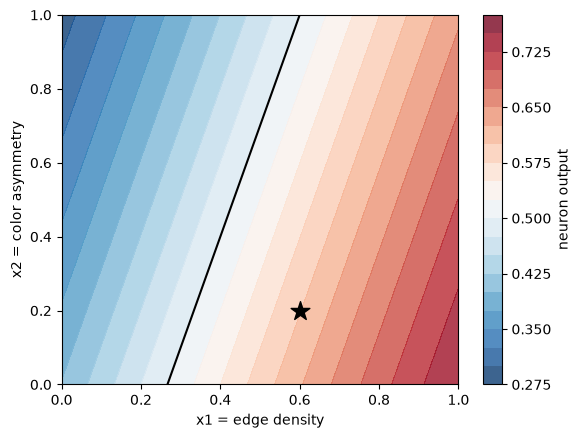

In [3]:
g1, g2 = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
_, p = neuron(np.stack([g1, g2], axis=-1), w, b)       # works on the whole grid at once

plt.contourf(g1, g2, p, levels=20, cmap="RdBu_r", alpha=0.8)
plt.colorbar(label="neuron output")
plt.contour(g1, g2, p, levels=[0.5], colors="k")       # the decision boundary: z = 0
plt.scatter(*x, c="k", marker="*", s=200)              # our lesion: 0.599
plt.xlabel("x1 = edge density"); plt.ylabel("x2 = color asymmetry");

### 2. XOR — what one line cannot do

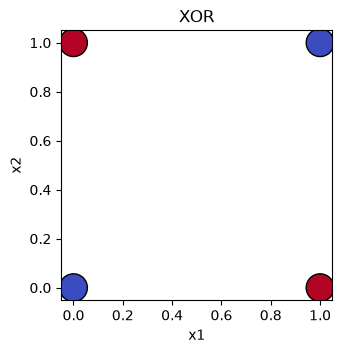

In [4]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])

plt.figure(figsize=(3.5, 3.5))
plt.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=400, edgecolors="k")
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("XOR");

In [5]:
def relu(z):
    return np.maximum(0, z)

W1 = np.array([[1, 1],
               [1, 1]], dtype=float)     # column j = weights of hidden neuron j
b1 = np.array([0, -1], dtype=float)
W2 = np.array([1, -2], dtype=float)

H = relu(X_xor @ W1 + b1)                # hidden layer: 4 inputs x 2 neurons
out = H @ W2
pd.DataFrame({"x1": X_xor[:, 0], "x2": X_xor[:, 1],
              "h1": H[:, 0], "h2": H[:, 1], "output": out, "XOR": y_xor})

,x1,x2,h1,h2,output,XOR
0,0.0,0.0,0.0,0.0,0.0,0
1,0.0,1.0,1.0,0.0,1.0,1
2,1.0,0.0,1.0,0.0,1.0,1
3,1.0,1.0,2.0,1.0,0.0,0


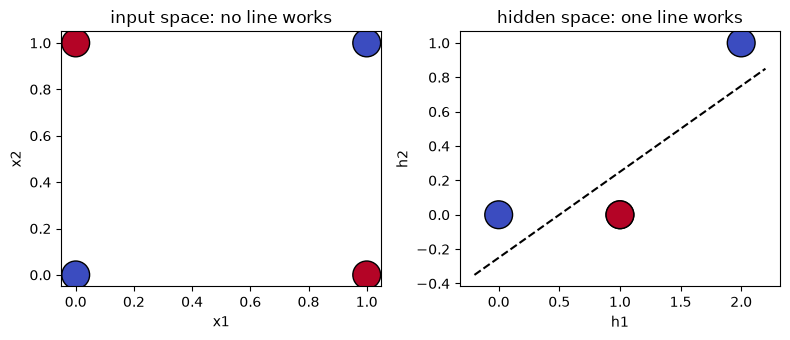

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap="coolwarm", s=400, edgecolors="k")
axes[0].set_title("input space: no line works"); axes[0].set_xlabel("x1"); axes[0].set_ylabel("x2")
axes[1].scatter(H[:, 0], H[:, 1], c=y_xor, cmap="coolwarm", s=400, edgecolors="k")
h1_line = np.linspace(-0.2, 2.2, 10)
axes[1].plot(h1_line, (h1_line - 0.5) / 2, "k--")       # output = h1 - 2*h2 = 0.5
axes[1].set_title("hidden space: one line works"); axes[1].set_xlabel("h1"); axes[1].set_ylabel("h2")
plt.tight_layout()

In [7]:
linear_out = (X_xor @ W1 + b1) @ W2               # same network, NO ReLU
collapsed = X_xor @ (W1 @ W2) + (b1 @ W2)          # one equivalent linear layer
print(linear_out, collapsed)                       # [2. 1. 1. 0.] twice -> not XOR
print(W1 @ W2, b1 @ W2)                            # [-1. -1.] 2.0

[2. 1. 1. 0.] [2. 1. 1. 0.]
[-1. -1.] 2.0


### 3. Forward pass, softmax, cross-entropy

In [8]:
def forward(x, W1, b1, W2, b2):
    z_h = x @ W1 + b1          # hidden pre-activations
    h = relu(z_h)              # hidden activations
    z_o = h @ W2 + b2          # output pre-activation
    return sigmoid(z_o), h, z_h

W1 = np.array([[0.5, -0.3],
               [0.3,  0.4]]); b1 = np.array([0.1, -0.3])
W2 = np.array([0.4, -0.2]);   b2 = 0.1

y_hat, h, z_h = forward(np.array([0.6, 0.2]), W1, b1, W2, b2)
print(z_h, h, y_hat)           # [ 0.46 -0.4 ] [0.46 0.  ] 0.570

[ 0.46 -0.4 ] [0.46 0.  ] 0.5705266031962988


In [9]:
def softmax(z):
    e = np.exp(z - z.max())    # subtract max: same result, no overflow
    return e / e.sum()

logits = np.array([1.0, 2.0, 0.5])          # Benign, Malignant, Indeterminate
print(np.exp(logits))                       # [2.718 7.389 1.649]
print(softmax(logits))                      # [0.231 0.629 0.14 ]

[2.718 7.389 1.649]
[0.231 0.629 0.14 ]


In [10]:
def cross_entropy(y_true_onehot, probs, eps=1e-9):
    probs = np.clip(probs, eps, 1 - eps)                 # avoid log(0)
    return -np.sum(y_true_onehot * np.log(probs))

y_true = np.array([0, 1, 0])                             # truth: Malignant
for probs in ([0.10, 0.70, 0.20], [0.005, 0.99, 0.005], [0.80, 0.10, 0.10]):
    print(probs, "->", round(cross_entropy(y_true, np.array(probs)), 3))   # 0.357 / 0.01 / 2.303

[0.1, 0.7, 0.2] -> 0.357
[0.005, 0.99, 0.005] -> 0.01
[0.8, 0.1, 0.1] -> 2.303


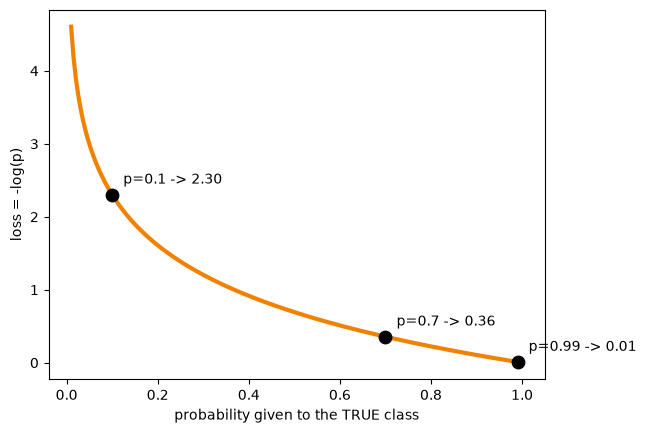

In [11]:
p = np.linspace(0.01, 1, 200)
plt.plot(p, -np.log(p), color="#F08200", lw=3)
for q in (0.10, 0.70, 0.99):
    plt.scatter(q, -np.log(q), s=80, color="k", zorder=3)
    plt.annotate(f"p={q} -> {-np.log(q):.2f}", (q, -np.log(q)), xytext=(8, 8), textcoords="offset points")
plt.xlabel("probability given to the TRUE class"); plt.ylabel("loss = -log(p)");

### 4. Gradient descent by hand

In [12]:
def descend(lr, w=0.0, steps=15):
    path = [w]
    for _ in range(steps):
        grad = 2 * (w - 3)       # slope of (w - 3)**2
        w = w - lr * grad        # one step downhill
        path.append(w)
    return np.array(path)

path = descend(lr=0.1)
print(path[:4])                  # [0.    0.6   1.08  1.464]
print(path[-1])                  # 2.894 after 15 steps -> close to 3

[0.    0.6   1.08  1.464]
2.894446883733504


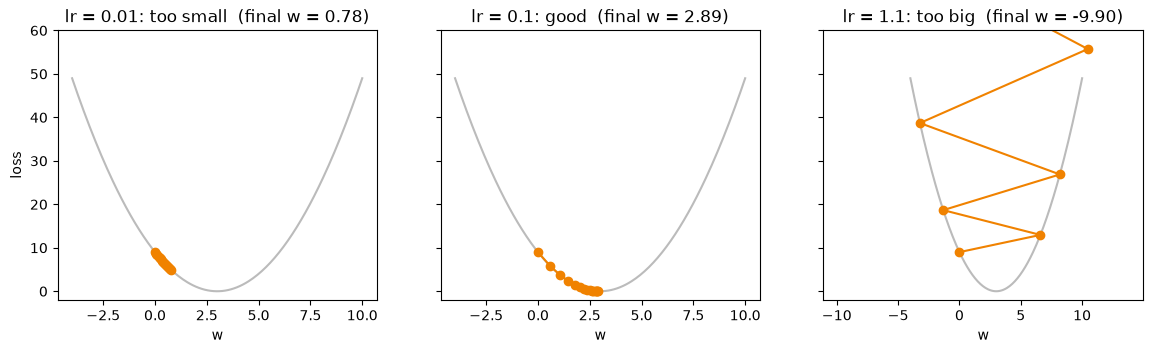

In [13]:
ws = np.linspace(-4, 10, 200)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, lr, title in zip(axes, [0.01, 0.1, 1.1], ["too small", "good", "too big"]):
    path = descend(lr, steps=8 if lr > 1 else 15)
    ax.plot(ws, (ws - 3) ** 2, color="#BBBBBB")
    ax.plot(path, (path - 3) ** 2, "o-", color="#F08200")
    ax.set_title(f"lr = {lr}: {title}  (final w = {path[-1]:.2f})")
    ax.set_ylim(-2, 60); ax.set_xlabel("w")
axes[0].set_ylabel("loss");

### 5. Backpropagation by hand — then let PyTorch check us

In [14]:
y = 1.0                                       # truth: malignant
z, y_hat = neuron(x, w, b)
loss = -np.log(y_hat)
print(f"forward : z={z:.3f}  y_hat={y_hat:.3f}  loss={loss:.3f}")      # 0.4  0.599  0.513

dz = y_hat - y                                # dLoss/dz for sigmoid + cross-entropy
grad_w = dz * x                               # chain rule: dLoss/dw = dLoss/dz * dz/dw = dz * x
grad_b = dz * 1
print(f"backward: dz={dz:.3f}  grad_w={grad_w}  grad_b={grad_b:.3f}")  # -0.401  [-0.241 -0.08 ]  -0.401

forward : z=0.400  y_hat=0.599  loss=0.513
backward: dz=-0.401  grad_w=[-0.241 -0.08 ]  grad_b=-0.401


In [15]:
lr = 1.0
w_new = w - lr * grad_w
b_new = b - lr * grad_b
z2, y_hat2 = neuron(x, w_new, b_new)
print(w_new, round(b_new, 3))                                  # [ 1.741 -0.42 ]  0.001
print(f"y_hat {y_hat:.3f} -> {y_hat2:.3f}   loss {loss:.3f} -> {-np.log(y_hat2):.3f}")   # 0.599 -> 0.723   0.513 -> 0.324

[ 1.741 -0.42 ] 0.001
y_hat 0.599 -> 0.723   loss 0.513 -> 0.324


In [16]:
import torch
import torch.nn as nn

xt = torch.tensor([0.6, 0.2])
wt = torch.tensor([1.5, -0.5], requires_grad=True)   # track gradients for these
bt = torch.tensor(-0.4, requires_grad=True)

y_hat_t = torch.sigmoid(xt @ wt + bt)                # forward, same formula
loss_t = -torch.log(y_hat_t)
loss_t.backward()                                    # backpropagation, automatic

print(y_hat_t.item(), loss_t.item())                 # 0.599  0.513
print(wt.grad, bt.grad)                              # tensor([-0.2408, -0.0803])  tensor(-0.4013)

0.5986876487731934 0.5130152702331543
tensor([-0.2408, -0.0803]) tensor(-0.4013)


### 6. A real (tiny) network learns a curved boundary

In [17]:
from sklearn.datasets import make_moons

Xm, ym = make_moons(n_samples=400, noise=0.2, random_state=0)
Xm_t = torch.tensor(Xm, dtype=torch.float32)
ym_t = torch.tensor(ym)

def make_net(hidden):
    torch.manual_seed(0)
    if hidden == 0:
        return nn.Linear(2, 2)                            # no hidden layer = logistic regression
    return nn.Sequential(nn.Linear(2, hidden), nn.ReLU(), nn.Linear(hidden, 2))

net = make_net(8)
net

Sequential(
  (0): Linear(in_features=2, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=2, bias=True)
)

In [18]:
def train(net, X, y, epochs=1000, lr=0.01):
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    for epoch in range(epochs):
        optimizer.zero_grad()            # 1. forget old gradients
        loss = loss_fn(net(X), y)        # 2. forward + loss
        loss.backward()                  # 3. backprop
        optimizer.step()                 # 4. w <- w - lr * grad  (Adam's version)
    return loss.item()

def plot_boundary(net, ax, title):
    g1, g2 = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
    grid = torch.tensor(np.c_[g1.ravel(), g2.ravel()], dtype=torch.float32)
    with torch.no_grad():
        p = torch.softmax(net(grid), dim=1)[:, 1].reshape(g1.shape)
    ax.contourf(g1, g2, p, levels=20, cmap="RdBu_r", alpha=0.7)
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", s=10, edgecolors="k", linewidths=0.3)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

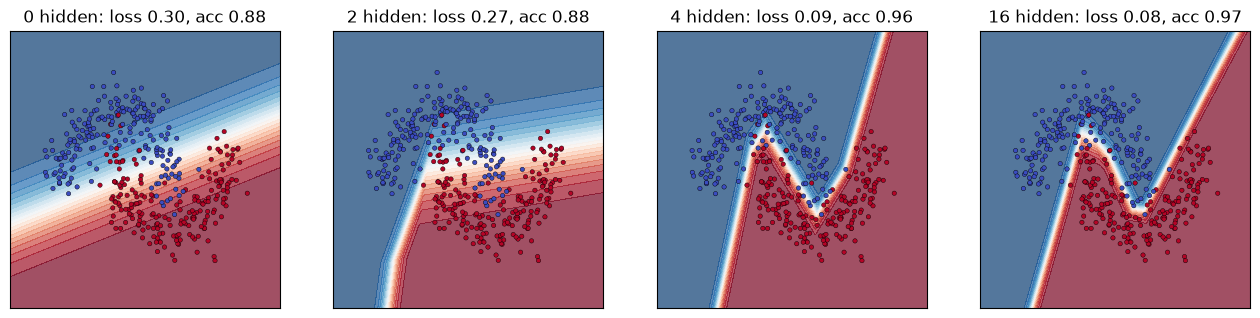

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, hidden in zip(axes, [0, 2, 4, 16]):
    net = make_net(hidden)
    final_loss = train(net, Xm_t, ym_t)
    with torch.no_grad():
        acc = (net(Xm_t).argmax(1) == ym_t).float().mean().item()
    plot_boundary(net, ax, f"{hidden} hidden: loss {final_loss:.2f}, acc {acc:.2f}")
# acc: 0 hidden 0.88 (a line) · 2 hidden 0.88 · 4 hidden 0.96 · 16 hidden 0.97

### 7. Back to MILK10k — Session 5's 33 features

In [ ]:
from PIL import Image
from scipy import ndimage

# ---- Session 5 ---------------------------------------------------------------
def color_stats(rgb):
    return np.concatenate([rgb.mean(axis=(0, 1)), rgb.std(axis=(0, 1))])

def color_histogram(rgb, bins=8):
    n_pixels = rgb.shape[0] * rgb.shape[1]
    return np.concatenate([np.histogram(rgb[:, :, c], bins=bins, range=(0, 256))[0] / n_pixels
                           for c in range(3)])

def texture_features(rgb):
    gray = rgb.mean(axis=2)
    gx, gy = ndimage.sobel(gray, axis=1), ndimage.sobel(gray, axis=0)
    local_mean = ndimage.uniform_filter(gray, size=9)
    local_sq_mean = ndimage.uniform_filter(gray**2, size=9)
    return np.array([np.hypot(gx, gy).mean(),
                     (local_sq_mean - local_mean**2).mean(),
                     ndimage.laplace(gray).var()])

def extract_features(isic_id):
    rgb = np.array(Image.open(config.image_path(isic_id)).convert("RGB").resize((200, 150)), dtype=float)
    return np.concatenate([color_stats(rgb), color_histogram(rgb), texture_features(rgb)])
# ------------------------------------------------------------------------------------------

df = milk10k.load_metadata()
gt = milk10k.load_gt()
train_df, val_df, test_df = milk10k.make_splits(df, gt, seed=0)            # Session 3: leak-free
train_df, val_df, test_df = [d[d["image_type"] == "dermoscopic"].reset_index(drop=True)
                             for d in (train_df, val_df, test_df)]        # one image per lesion

cache = ROOT / "session_06_neural_networks" / "_output" / "features_33.npz"
if cache.exists():
    data = np.load(cache, allow_pickle=True)
else:
    t0 = time.perf_counter()
    data = {f"X_{n}": np.stack([extract_features(i) for i in d["isic_id"]])
            for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
    cache.parent.mkdir(exist_ok=True)
    np.savez(cache, **data)
    print(f"{time.perf_counter() - t0:.0f} s")

X_train, X_val, X_test = data["X_train"], data["X_val"], data["X_test"]
print(X_train.shape, X_val.shape, X_test.shape)     # (3593, 33) (599, 33) (1048, 33)

(3593, 33) (599, 33) (1048, 33)


In [21]:
from sklearn.preprocessing import StandardScaler

CLASSES = ["Benign", "Indeterminate", "Malignant"]
to_int = {c: i for i, c in enumerate(CLASSES)}
y_train = torch.tensor(train_df["diagnosis_1"].map(to_int).to_numpy())
y_val = torch.tensor(val_df["diagnosis_1"].map(to_int).to_numpy())
y_test = torch.tensor(test_df["diagnosis_1"].map(to_int).to_numpy())

scaler = StandardScaler().fit(X_train)                       # train only
Xtr = torch.tensor(scaler.transform(X_train), dtype=torch.float32)
Xva = torch.tensor(scaler.transform(X_val), dtype=torch.float32)
Xte = torch.tensor(scaler.transform(X_test), dtype=torch.float32)

print(Xtr.dtype, Xtr.shape, y_train[:10])
print(torch.bincount(y_train))                                # tensor([1016,   83, 2494])

torch.float32 torch.Size([3593, 33]) tensor([2, 0, 2, 0, 2, 2, 0, 0, 2, 2])
tensor([1016,   83, 2494])


In [22]:
class_weights = len(y_train) / (3 * torch.bincount(y_train).float())
class_weights                                                  # tensor([ 1.18, 14.43,  0.48])

tensor([ 1.1788, 14.4297,  0.4802])

### 8. An MLP on MILK10k — mini-batches, epochs, curves

In [23]:
def make_mlp(hidden=(64,), dropout=0.0, seed=0):
    torch.manual_seed(seed)                     # same initial weights for everyone
    layers, d_in = [], 33
    for h in hidden:
        layers += [nn.Linear(d_in, h), nn.ReLU()]
        if dropout:
            layers.append(nn.Dropout(dropout))
        d_in = h
    layers.append(nn.Linear(d_in, 3))           # 3 logits, no softmax (it's inside the loss)
    return nn.Sequential(*layers)

model = make_mlp()
print(model)
print(sum(p.numel() for p in model.parameters()))        # 2371

Sequential(
  (0): Linear(in_features=33, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=3, bias=True)
)
2371


In [24]:
from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(TensorDataset(Xtr, y_train), batch_size=64, shuffle=True)
print(len(train_loader))                                  # 57 batches per epoch
xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)                                 # torch.Size([64, 33]) torch.Size([64])

57
torch.Size([64, 33]) torch.Size([64])


In [25]:
from sklearn.metrics import f1_score, accuracy_score

def fit(model, epochs=50, lr=1e-3, weight_decay=0.0, batch_size=64):
    loader = DataLoader(TensorDataset(Xtr, y_train), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            val_logits = model(Xva)
            history.append({"epoch": epoch,
                            "train_loss": total / len(Xtr),
                            "val_loss": loss_fn(val_logits, y_val).item(),
                            "val_f1": f1_score(y_val, val_logits.argmax(1), average="macro")})
    return pd.DataFrame(history).set_index("epoch")

t0 = time.perf_counter()
model = make_mlp()
hist = fit(model)
print(f"{time.perf_counter() - t0:.0f} s")
hist.iloc[[0, 9, 19, 29, 39, 49]].round(3)        # last row: train 0.625, val loss 1.068, val F1 0.493

3 s


,train_loss,val_loss,val_f1
epoch,,,
0,1.040,0.988,0.456
9,0.777,0.937,0.457
19,0.725,0.973,0.475
29,0.682,1.023,0.494
39,0.654,1.003,0.489
49,0.625,1.068,0.493


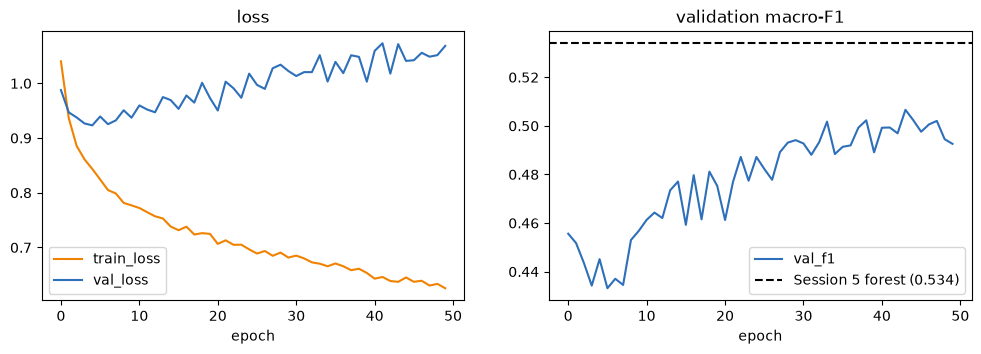

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
hist[["train_loss", "val_loss"]].plot(ax=axes[0], color=["#F08200", "#2E6FBA"], title="loss")
hist["val_f1"].plot(ax=axes[1], color="#2E6FBA", title="validation macro-F1")
axes[1].axhline(0.534, color="k", ls="--", label="Session 5 forest (0.534)")
axes[1].legend();

In [27]:
model.eval()
with torch.no_grad():
    val_pred = model(Xva).argmax(1)
mlp_val_f1 = f1_score(y_val, val_pred, average="macro")
print(f"MLP val macro-F1 = {mlp_val_f1:.3f}   (Session 5: majority 0.272, logreg 0.437, kNN 0.474, forest 0.534)")   # 0.493

MLP val macro-F1 = 0.493   (Session 5: majority 0.272, logreg 0.437, kNN 0.474, forest 0.534)


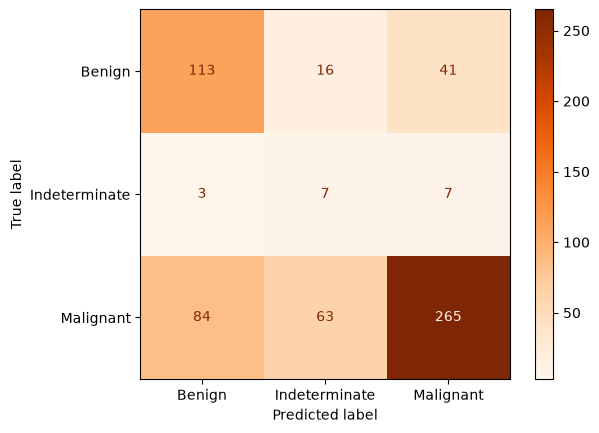

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_val, val_pred, display_labels=CLASSES, cmap="Oranges");

### 9. Overfitting on purpose — and three cures

75267


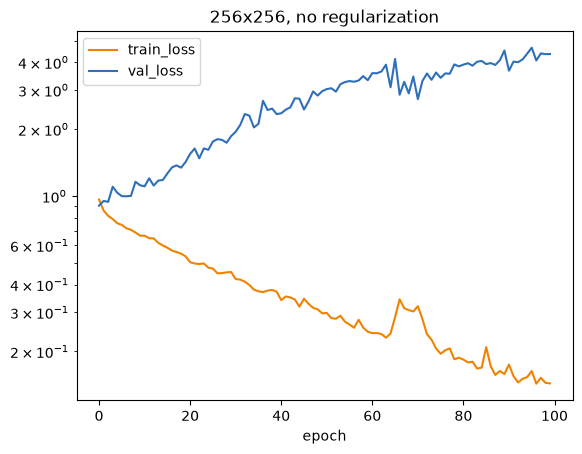

In [29]:
big = make_mlp(hidden=(256, 256))
print(sum(p.numel() for p in big.parameters()))           # 75267 weights
hist_big = fit(big, epochs=100)
hist_big[["train_loss", "val_loss"]].plot(color=["#F08200", "#2E6FBA"], logy=True,
                                          title="256x256, no regularization");

{'train_loss': 0.144, 'val_loss': 4.355, 'val_f1': 0.525}
{'train_loss': 0.402, 'val_loss': 2.504, 'val_f1': 0.546}


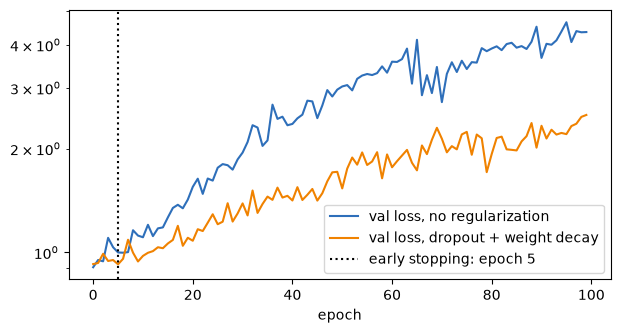

In [30]:
reg = make_mlp(hidden=(256, 256), dropout=0.3)
hist_reg = fit(reg, epochs=100, weight_decay=1e-4)

fig, ax = plt.subplots(figsize=(7, 3.5))
hist_big["val_loss"].plot(ax=ax, label="val loss, no regularization", color="#2E6FBA", logy=True)
hist_reg["val_loss"].plot(ax=ax, label="val loss, dropout + weight decay", color="#F08200")
best_epoch = hist_reg["val_loss"].idxmin()
ax.axvline(best_epoch, color="k", ls=":", label=f"early stopping: epoch {best_epoch}")
ax.legend();
print(hist_big.iloc[-1].round(3).to_dict())     # train 0.144, val loss 4.355, val F1 0.525
print(hist_reg.iloc[-1].round(3).to_dict())     # train 0.402, val loss 2.504, val F1 0.546

### 10. The test set — once — and the scoreboard

In [31]:
with torch.no_grad():
    test_pred = model(Xte).argmax(1)
test_acc = accuracy_score(y_test, test_pred)
test_f1 = f1_score(y_test, test_pred, average="macro")
print(f"TEST accuracy = {test_acc:.3f}   TEST macro-F1 = {test_f1:.3f}")     # 0.617   0.472

baseline = json.loads((ROOT / "session_05_classical_ml" / "_output" / "baseline_scores.json").read_text())
scoreboard = pd.DataFrame({
    "Session 5 - random forest (33 features)": [baseline["val_macro_f1"], baseline["test_macro_f1"]],
    "Session 6 - MLP 33-64-3 (33 features)": [round(mlp_val_f1, 3), round(test_f1, 3)],
}, index=["val macro-F1", "test macro-F1"]).T
scoreboard

TEST accuracy = 0.617   TEST macro-F1 = 0.472


,val macro-F1,test macro-F1
Session 5 - random forest (33 features),0.534,0.495
Session 6 - MLP 33-64-3 (33 features),0.493,0.472


In [32]:
out_dir = ROOT / "session_06_neural_networks" / "_output"
out_dir.mkdir(exist_ok=True)
scores = {"model": "MLP 33-64-3 on Session 5's 33 handcrafted features",
          "val_macro_f1": round(float(mlp_val_f1), 3),
          "test_accuracy": round(float(test_acc), 3),
          "test_macro_f1": round(float(test_f1), 3)}
(out_dir / "mlp_scores.json").write_text(json.dumps(scores, indent=2))
scores

{'model': "MLP 33-64-3 on Session 5's 33 handcrafted features",
 'val_macro_f1': 0.493,
 'test_accuracy': 0.617,
 'test_macro_f1': 0.472}

### 11. Mini challenge — tune it

Change **one thing at a time**, train, and note the final **validation** macro-F1:

1. learning rate: `lr=0.1`, then `lr=1e-5`
2. width: `hidden=(4,)`, then `hidden=(256,)`
3. depth: `hidden=(64, 64)`

Number to beat: Session 5's random forest, **0.534**. The test set stays closed.

### Homework · Before Session 7

1. Add your MLP's validation and test macro-F1 to the scoreboard, next to Session 5's forest.
2. Read the docs of nn.Conv2d: which arguments are Session 4's kernel size, stride and padding?
3. Train the MLP on raw pixels (32×32×3 = 3,072 numbers). Better or worse than 33 features? Why?